# R3. TF prioritization benchmark: four scenarios and nonlinear criteria

This notebook reproduces, from saved result files, every number that the manuscript quotes for

* the comparison of four scenarios in the TF prioritization benchmark (Results, "TF prioritization efficiency is enhanced with GeneSys-generated profiles over scRNA-seq data"; **Figure 5**; Methods, "Pseudobulk and scVI scenarios for the prioritization benchmark"),
* **Experiment 5**, in silico knockout regulator ranking (**Figure S11A**),
* **Experiment 6**, nonlinear network inference with GRNBoost2 (**Figure S11A**),
* **Experiment 7**, genome-wide gold-standard recall (**Figure S11B to S11D**).

The heavy steps (scVI training, LIMA and GRNBoost2 fits, the knockout sweep) were run as cluster jobs with the scripts in `../codes/`. The commands are shown but not executed here. The scoring steps that are cheap (R50 of the DE criteria, R50 and genome-wide recall of the knockout, the permutation baseline, the hypergeometric tests) are recomputed in this notebook from the stored tables. Each number is followed by an `assert`, so the notebook fails if a result file and the manuscript disagree.

| Claim in the manuscript | Section |
|---|---|
| 1,495 TFs, 140 gold-standard TFs, 17,513 genes; permutation baseline 741 | 1 |
| scVI trained for 72 epochs; every scenario with the cell numbers of the Figure 4 batch | 2 |
| Figure 4 marker criterion and its Python port (same fold changes; 21,543 of 21,568 scRNA-seq markers and 18,554 of 18,555 GeneSys markers) | 3 |
| LIMA centrality: GeneSys lowest mean R50 and best on four of five metrics; scVI, unregularized and pseudobulk similar to one another | 4.1 |
| DE (strongest marker first): GeneSys and the unregularized data about equal under both statistics; pseudobulk slightly lower; scVI has no R50 (14 gold-standard TFs; 60 markers per cluster against 176 to 214) | 4.2 |
| GeneSys has the lowest mean R50 of the four scenarios over the LIMA criteria of Figure 5 | 4.3 |
| Why DE alone is not sufficient: 68 and 59 of the 140 gold-standard TFs not among the markers; AUC of 0.95 or more for 50% and 6% of the TF markers; average difference about 8% smaller on generated data; AUC ordering does not separate the gold-standard TFs on generated data | 4.4 |
| GRNBoost2: every centrality metric behind LIMA, eigenvector at the permutation baseline | 5 |
| Knockout: all three scores behind four of the five LIMA metrics, classifier effect behind the permutation baseline | 6 |
| Genome-wide: knockout generative effect 11 of 140 in the top 400, 3.4 times chance, p = 4 × 10⁻⁴ | 7.1 |
| Expression-level audit: 1 gold-standard TF by mean expression, 9 after adjustment against 3 expected, 34 TFs against 34 expected, Spearman 0.41 | 7.2 |
| Genome-wide recall of LIMA degree centrality and DE in the four scenarios | 7.3 |

In [1]:
import os, json
import numpy as np
import pandas as pd
from scipy.stats import hypergeom, rankdata, spearmanr
from IPython.display import Image, display

R = os.path.join('..', 'results')                             # result files of the revision folder
REPO_DATA = os.path.join('..', '..', 'supp_data')             # supplementary data of the repository
P = os.path.join(R, 'prioritization')                         # files of this notebook
CONDS = ['genesys', 'scrnaseq', 'pseudobulk', 'scvi']         # scrnaseq = unregularized scRNA-seq data
NICE = {'genesys': 'GeneSys-generated', 'scrnaseq': 'unregularized scRNA-seq',
        'pseudobulk': 'pseudobulk', 'scvi': 'scVI-denoised'}

# Figures are drawn by codes/exp24_manuscript_figures.py from the result tables in R
import importlib.util
os.environ['GENESYS_RESULTS'] = os.path.abspath(R)
os.environ['GENESYS_FIGURES'] = os.path.abspath(os.path.join(R, 'figures'))
_spec = importlib.util.spec_from_file_location('figures', os.path.join('..', 'codes', 'exp24_manuscript_figures.py'))
figures = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(figures)

def r50_scan(ranked_genes, gold, target=70):
    """1-based position of the 70th gold-standard TF in a ranked list (R50)."""
    n = 0
    for i, g in enumerate(ranked_genes, start=1):
        if g in gold:
            n += 1
            if n == target:
                return i
    return None

## 1. Reference lists and the permutation baseline

* **TFs**: the genes of the root atlas that carry a TF annotation in the ThaleMine list (`supp_data/TF_list/Kay_TF_thalemine_annotations.csv`).
* **Gold standard**: the TFs shared by the MINI-EX list and the StringDB list (`supp_data/gold_standard_for_benchmarking/`); the intersection used by the scoring scripts is stored as `Gold_Standard_Root_TF_MINI_EX_StringDB.csv`.
* **R50**: the position, in a ranked list of TFs, at which the 70th of the 140 gold-standard TFs appears. Lower is better.
* **Permutation baseline**: mean R50 over 1,000 random orderings of the TFs.

In [2]:
genes = pd.read_csv(os.path.join(P, 'gene_list_1108.csv'))['features'].tolist()
tf_annot = set(pd.read_csv(os.path.join(REPO_DATA, 'TF_list', 'Kay_TF_thalemine_annotations.csv'))['GeneID'])
exptf = [g for g in dict.fromkeys(genes) if g in tf_annot]            # TFs present in the atlas, in gene-list order
gold = set(pd.read_csv(os.path.join(P, 'Gold_Standard_Root_TF_MINI_EX_StringDB.csv'))['GeneID'])

print('genes:', len(genes), '| TFs:', len(exptf), '| gold-standard TFs:', len(gold))
assert len(genes) == 17513 and len(exptf) == 1495 and len(gold) == 140
assert gold <= set(exptf)                                             # every gold-standard TF is one of the 1,495 TFs

# the gold standard is the intersection of the two published lists
gd = os.path.join(REPO_DATA, 'gold_standard_for_benchmarking')
miniex = set(pd.read_csv(os.path.join(gd, 'Gold_Standard_Root_TF_MINI_EX.csv'))['GeneID'])
stringdb = set(pd.read_csv(os.path.join(gd, 'Gold_Standard_Root_TF_StringDB.csv'))['GeneID'])
print('MINI-EX:', len(miniex), '| StringDB:', len(stringdb), '| shared:', len(miniex & stringdb))
assert (miniex & stringdb) == gold

genes: 17513 | TFs: 1495 | gold-standard TFs: 140
MINI-EX: 143 | StringDB: 209 | shared: 140


In [3]:
# permutation baseline, as in exp13_fig4_r50.py (1,000 permutations, seed 0)
rng = np.random.RandomState(0)
arr = np.array(exptf, dtype=object)
perm = np.mean([r50_scan(arr[rng.permutation(len(arr))], gold) for _ in range(1000)])
print(f'permutation baseline: {perm:.1f}')
assert round(perm) == 741

ko_summary = json.load(open(os.path.join(P, 'exp17_knockout', 'exp17_summary.json')))
assert round(ko_summary['permutation_r50']) == 741                    # the value stored by the scoring script
PERM = 741

permutation baseline: 740.8


## 2. The four scenarios

Every scenario supplies cell-by-gene matrices on the same scale (expression between 0 and 1, the 17,513 genes of the atlas) for the same states (cell type by time bin).

* **Unregularized scRNA-seq data**: the cells of the root atlas, as prepared for GeneSys training (notebook 1).
* **Pseudobulk**: each profile is the mean of 50 scRNA-seq profiles sampled with replacement from one cell type and time bin (`--boot-cells 50` in `exp14_condition_pipeline.py`).
* **scVI-denoised**: scVI is trained on the raw UMI counts of the atlas with the sequencing sample as batch key and 30 latent dimensions (`exp15_scvi_prepare.py`). The normalized expression returned by the decoder (library size 10,000) is log-transformed and scaled to the unit interval.
* **GeneSys-generated**: the published LIMA tables of notebook 12 and the published marker table of Figure 4 are used as they are.

For the LIMA criteria, `exp14_condition_pipeline.py --mode lima` is a port of notebook 12 (the scRNA-seq version): for each cell type and transition it solves the least-squares problem on 200 rows per state, averages the solutions over 55 batches drawn from the full atlas (as the scRNA-seq notebook 12 does), keeps the entries with |z| > 3 (z-score over all entries of the averaged matrix) and computes the centralities of the TF-by-TF network. In the unregularized, pseudobulk and scVI scenarios the rows of the two states are sampled independently; GeneSys-generated rows are paired by trajectory.

For the DE criteria, the GeneSys-generated and unregularized scenarios use the marker tables of Figure 4 themselves. The pseudobulk and scVI batches are built with the composition of the Figure 4 batch (2,000 trajectories: one stem-cell profile each at t0, and 169 to 226 profiles for each cell type and time bin).

In [4]:
# Commands used on the cluster (not executed here).
# scVI (dedicated scvi conda environment, one GPU):
#   sbatch --job-name=exp15_scvi --gres=gpu:nvidia_h200:1 experiments/slurm/run_scvi_gpu.sh experiments/exp15_scvi_prepare.py
# LIMA and centralities for the two additional scenarios, one job per transition (t0-t1, t1-t3, t3-t5, t5-t7, t7-t9), 55 batches:
#   sbatch --cpus-per-task=16 experiments/slurm/run_cpu.sh experiments/exp14_condition_pipeline.py --condition pseudobulk --mode lima --transition t1-t3 --save-ctw --n-reps 55
#   sbatch --cpus-per-task=16 experiments/slurm/run_cpu.sh experiments/exp14_condition_pipeline.py --condition scvi       --mode lima --transition t1-t3 --save-ctw --n-reps 55
# Reproduction check: the scRNA-seq LIMA through the same pipeline
#   sbatch --cpus-per-task=16 experiments/slurm/run_cpu.sh experiments/exp14_condition_pipeline.py --condition raw --mode lima --transition t1-t3 --n-reps 55
# DE markers with the Figure 4 criterion for the two additional scenarios (batches with the Figure 4 composition):
#   sbatch experiments/slurm/run_cpu.sh experiments/exp14_condition_pipeline.py --condition pseudobulk --mode de --seurat
#   sbatch experiments/slurm/run_cpu.sh experiments/exp14_condition_pipeline.py --condition scvi       --mode de --seurat
# R50 scoring and the benchmark table (experiments/slurm/post_l55.sh):
#   python experiments/exp13_fig4_r50.py                      # GeneSys and unregularized, published LIMA tables (exp13_gate_r50.csv)
#   python experiments/exp13_fig4_r50.py --label pseudobulk --lima-prefix pseudobulk_TF_GRN_centrality --lima-dir experiments/results/exp14_conditions
#   python experiments/exp13_fig4_r50.py --label scvi       --lima-prefix scvi_TF_GRN_centrality       --lima-dir experiments/results/exp14_conditions
#   python experiments/exp13_fig4_r50.py --label raw_gate   --lima-prefix raw_TF_GRN_centrality        --lima-dir experiments/results/exp14_conditions
#   python experiments/exp20_fig4_expanded.py                 # assembles exp20_fig4_expanded_table.csv

In [5]:
# scVI was trained for 72 epochs, the scvi-tools default for this number of cells
elbo = pd.read_csv(os.path.join(P, 'scvi_elbo_train.csv'))
print('scVI training epochs logged:', len(elbo))
assert len(elbo) == 72

scVI training epochs logged: 72


## 3. The marker criterion of Figure 4 and its port

In Figure 4 the DE markers come from the author's notebook `DE_GeneSys_vs_scRNAseq.ipynb`, which calls

```r
FindAllMarkers(seu, max.cells.per.ident = 10000, only.pos = T, test.use = "roc")
```

on a batch of 2,000 trajectories (22,000 cells; the stem cells at t0 form one cluster and each cell type at each later time bin forms one, 101 clusters). All other parameters are at the Seurat v4 defaults: a log2 fold change of at least 0.25, detection in at least 10% of the cells of either group, and, for the ROC test, an AUC above 0.7. The notebook then ranks the markers within each cluster by AUC and by average expression difference.

To apply one procedure to all four scenarios, this call was ported to Python (`exp35_seurat_roc_markers.py`). The port computes, for each cluster against all other cells, the fold change as Seurat does (`log2(mean(expm1(x)) + 1)` of the two groups), the detection rates, the AUC (rank-sum form, rounded to three decimals) and the average difference, applies the three thresholds, and assigns the within-cluster ranks. To check the port, the cells stored in the two Seurat objects of Figure 4 (`X_root_integrated.rds` for the scRNA-seq batch, `P_root_integrated.rds` for the GeneSys-generated batch) were exported (`exp36_export_fig4_seurat.R`) and passed through it (`python experiments/exp35_seurat_roc_markers.py --validate-objects`). The comparison with the published marker tables gives:

In [6]:
val = json.load(open(os.path.join(P, 'exp35_seurat_port_validation_objects.json')))
show = ['tag', 'cells', 'rows_mine', 'rows_published', 'rows_common', 'only_mine', 'only_published',
        'max_abs_diff_avg_log2FC', 'max_abs_diff_myAUC', 'R50_port', 'R50_published']
for v in val:
    print(json.dumps({k: v[k] for k in show}))
raw_val, gen_val = val[0], val[1]
assert 'scRNA-seq' in raw_val['tag'] and 'GeneSys' in gen_val['tag']
for v in val:
    assert v['cells'] == 22000
    assert v['max_abs_diff_avg_log2FC'] < 1e-6                        # the fold changes are the same
    assert v['max_abs_diff_myAUC'] <= 0.01                            # Seurat subsamples the background to 10,000 cells
assert (raw_val['rows_common'], raw_val['rows_published']) == (21543, 21568)   # "21,543 of the 21,568 scRNA-seq markers"
assert (gen_val['rows_common'], gen_val['rows_published']) == (18554, 18555)   # "18,554 of the 18,555 GeneSys markers"
# R50 of the two DE criteria from the port table and from the published table
assert raw_val['R50_port'] == [382, 407] and raw_val['R50_published'] == [380, 403]
assert gen_val['R50_port'] == [309, 331] and gen_val['R50_published'] == [310, 331]

{"tag": "scRNA-seq (Figure 4 object)", "cells": 22000, "rows_mine": 21561, "rows_published": 21568, "rows_common": 21543, "only_mine": 18, "only_published": 25, "max_abs_diff_avg_log2FC": 7.65980306960401e-09, "max_abs_diff_myAUC": 0.007000000000000006, "R50_port": [382, 407], "R50_published": [380, 403]}
{"tag": "GeneSys (Figure 4 object)", "cells": 22000, "rows_mine": 18554, "rows_published": 18555, "rows_common": 18554, "only_mine": 0, "only_published": 1, "max_abs_diff_avg_log2FC": 5.035480254989011e-09, "max_abs_diff_myAUC": 0.007000000000000006, "R50_port": [309, 331], "R50_published": [310, 331]}


The markers that differ lie at the AUC threshold: with `max.cells.per.ident = 10000` Seurat tests each cluster against a random subsample of 10,000 background cells, whereas the port uses all of them, so the AUC differs in the third decimal.

## 4. R50 across the four scenarios (Figure 5)

`exp20_fig4_expanded_table.csv` holds the R50 of every criterion. The LIMA rows come from the `exp13_fig4_r50.py` runs; the DE rows are computed from the two marker tables of Figure 4 (GeneSys-generated, unregularized) and from the two tables built with the port (pseudobulk, scVI).

In [7]:
tab = pd.read_csv(os.path.join(P, 'exp20_fig4_expanded_table.csv'))
lima = tab[tab['method'] == 'LIMA'].pivot(index='strategy', columns='condition', values='R50')[CONDS]

lima = lima.loc[['degree_centrality', 'out_centrality', 'in_centrality', 'betweenness_centrality', 'eigenvector_centrality']]
lima.astype(int)

condition,genesys,scrnaseq,pseudobulk,scvi
strategy,,,,
degree_centrality,314,365,345,429
out_centrality,375,444,427,417
in_centrality,327,330,319,420
betweenness_centrality,248,256,275,336
eigenvector_centrality,432,536,549,456


### 4.1 LIMA centrality

In [8]:
# the LIMA rows of the table are the "All" (system-wide) rows of the three scoring runs
src = pd.concat([pd.read_csv(os.path.join(P, f)) for f in
                 ['exp13_gate_r50.csv', 'exp13_r50_pseudobulk.csv', 'exp13_r50_scvi.csv']])
src = src[(src['panel'] == 'All') & (src['method'] == 'LIMA')].pivot(index='strategy', columns='condition', values='R50')
assert (src.loc[lima.index, CONDS].values == lima.values).all()

lima_mean = lima.mean().round().astype(int)
print('mean R50 over the five centrality metrics'); print(lima_mean.rename(NICE).to_string())
assert lima_mean.to_dict() == {'genesys': 339, 'scrnaseq': 386, 'pseudobulk': 383, 'scvi': 412}

order = list(lima.mean().sort_values().index)
print('\norder, best first:', [NICE[c] for c in order])
assert order == ['genesys', 'pseudobulk', 'scrnaseq', 'scvi']
# "unregularized scRNA-seq data and pseudobulk averages performed similarly to each other and scVI-denoised
# expression gave the highest mean R50 of the four"
m = lima.mean()
print('scRNA-seq against pseudobulk:', round(m['scrnaseq'] - m['pseudobulk'], 1), '; GeneSys ahead of the nearest by:', round(m.drop('genesys').min() - m['genesys'], 1))
assert abs(m['scrnaseq'] - m['pseudobulk']) < 5 and order[-1] == 'scvi'

best = lima.idxmin(axis=1)
print('\nbest scenario per metric'); print(best.to_string())
assert (best == 'genesys').sum() == 4                                 # "the best scenario on four of the five metrics"

# GeneSys-generated against the unregularized data, metric by metric
assert (lima['genesys'] < lima['scrnaseq']).all()

mean R50 over the five centrality metrics
condition
GeneSys-generated          339
unregularized scRNA-seq    386
pseudobulk                 383
scVI-denoised              412

order, best first: ['GeneSys-generated', 'pseudobulk', 'unregularized scRNA-seq', 'scVI-denoised']
scRNA-seq against pseudobulk: 3.2 ; GeneSys ahead of the nearest by: 43.8

best scenario per metric
strategy
degree_centrality            genesys
out_centrality               genesys
in_centrality             pseudobulk
betweenness_centrality       genesys
eigenvector_centrality       genesys


**Reproduction check.** The scRNA-seq LIMA tables of Figure 4 come from the author's scRNA-seq notebook 12. Running the same scenario through `exp14_condition_pipeline.py` (55 batches from the full atlas) gives the values below. The batches are drawn at random and the notebook sets no seed, so the draw cannot be replayed; the pipeline also takes a fixed 200 rows per cell type where the notebook takes the 169 to 226 that fall in each batch. The pipeline itself is seeded, but two runs of the same command (2026-10-01 and 2026-10-26) gave degree, out-degree, in-degree and eigenvector R50 values that differ by 3 to 14 ranks, so these values agree with Figure 4 to within that run-to-run spread, not exactly.

In [9]:
gate = pd.read_csv(os.path.join(P, 'exp13_r50_raw_gate.csv'))
gate = gate[(gate['panel'] == 'All') & (gate['method'] == 'LIMA')].set_index('strategy')['R50'].loc[lima.index]
chk = pd.DataFrame({'pipeline (55 batches)': gate.astype(int), 'Figure 4 (notebook 12)': lima['scrnaseq'].astype(int)})
print(chk.to_string())
assert list(chk['pipeline (55 batches)']) == [366, 425, 323, 273, 531]
assert list(chk['Figure 4 (notebook 12)']) == [365, 444, 330, 256, 536]

                        pipeline (55 batches)  Figure 4 (notebook 12)
strategy                                                             
degree_centrality                         366                     365
out_centrality                            425                     444
in_centrality                             323                     330
betweenness_centrality                    273                     256
eigenvector_centrality                    531                     536


### 4.2 Differential expression

The R50 of the two DE criteria is recomputed here from the four marker tables, following the author's notebook 13 (`13-GeneSys_Top_Regulators_Plots`): the markers are restricted to the 1,495 TFs, the within-cluster ranks of each TF are averaged over the clusters in which it is a marker, the TFs are ordered by ascending mean rank (rank 1 is the strongest marker of a cluster, so the strongest markers come first), and R50 is read from that list. Notebook 13 had sorted the mean rank in descending order, with the weakest markers first, which gave 310 and 331 (GeneSys) and 380 and 403 (scRNA-seq); the notebook and `exp13_fig4_r50.py` now use the ascending order.

In [10]:
files = {'genesys': 'GeneSys_P_root_markers_ROC.csv', 'scrnaseq': 'Input_X_root_markers_ROC.csv',      # Figure 4 tables
         'pseudobulk': 'pseudobulk_markers_ROC_fig4.csv', 'scvi': 'scvi_markers_ROC_fig4.csv'}           # port
exptf_set = set(exptf)
de_r50, cover = {}, {}
for cond, stem in files.items():
    m = pd.read_csv(os.path.join(P, 'markers', stem))
    # the three thresholds of the criterion hold in every table
    assert m['avg_log2FC'].min() >= 0.25 and m['myAUC'].min() > 0.7 and m[['pct.1', 'pct.2']].max(axis=1).min() >= 0.1
    tf = m[m['gene'].isin(exptf_set)]
    agg = tf.groupby('gene', as_index=False).agg(myAUC_rank=('myAUC_rank', 'mean'), avg_diff_rank=('avg_diff_rank', 'mean'))
    n_gold = int(agg['gene'].isin(gold).sum())
    cover[cond] = dict(markers=len(m), clusters=m['cluster'].nunique(),
                       genes_per_cluster=round(len(m) / m['cluster'].nunique()), TFs=len(agg), gold_TFs=n_gold)
    de_r50[cond] = {col: (r50_scan(agg.sort_values(col, ascending=True, kind='stable')['gene'].values, gold)
                          if n_gold >= 70 else None) for col in ['myAUC_rank', 'avg_diff_rank']}
cover = pd.DataFrame(cover).T
de = pd.DataFrame(de_r50)
print(cover.rename(index=NICE).to_string()); print(); print(de.rename(columns=NICE).to_string())

                         markers  clusters  genes_per_cluster  TFs  gold_TFs
GeneSys-generated          18555       101                184  337        72
unregularized scRNA-seq    21568       101                214  449        81
pseudobulk                 17744       101                176  353        73
scVI-denoised               6089       101                 60   53        14

               GeneSys-generated  unregularized scRNA-seq  pseudobulk scVI-denoised
myAUC_rank                   316                      318         330          None
avg_diff_rank                295                      287         313          None


In [11]:
# identical to the stored tables
stored_cov = pd.read_csv(os.path.join(P, 'exp20_de_marker_coverage.csv')).set_index('condition')
assert (stored_cov.loc[CONDS, cover.columns].values == cover.loc[CONDS].values.astype(int)).all()
stored_de = tab[tab['method'] == 'DE'].pivot(index='strategy', columns='condition', values='R50')
for c in ['genesys', 'scrnaseq', 'pseudobulk']:
    for s in ['myAUC_rank', 'avg_diff_rank']:
        assert stored_de.loc[s, c] == de.loc[s, c]
assert stored_de['scvi'].isna().all()

# the values: the GeneSys-generated and unregularized values are those of Figure 4
assert de['genesys'].to_dict() == {'myAUC_rank': 316, 'avg_diff_rank': 295}
assert de['scrnaseq'].to_dict() == {'myAUC_rank': 318, 'avg_diff_rank': 287}
assert de['pseudobulk'].to_dict() == {'myAUC_rank': 330, 'avg_diff_rank': 313}

# "GeneSys-generated profiles and the unregularized data ranked the gold-standard TFs about equally well under both DE statistics"
assert ((de['genesys'] - de['scrnaseq']).abs() <= 10).all()
# "and pseudobulk averages ranked them slightly lower": behind both by fewer than 30 ranks
gapd = de['pseudobulk'] - de[['genesys', 'scrnaseq']].min(axis=1)
print('pseudobulk minus the better of GeneSys and scRNA-seq:', gapd.to_dict())
assert (gapd > 0).all() and gapd.max() < 30

# scVI: "only 14 of the 140 gold-standard TFs, fewer than the 70 at which R50 is read"
assert cover.loc['scvi', 'gold_TFs'] == 14 and de['scvi'].isna().all()
# "retained 60 genes per cluster against 176 to 214 in the other three", 101 clusters in every scenario
assert cover.loc['scvi', 'genes_per_cluster'] == 60
others = cover.loc[['genesys', 'scrnaseq', 'pseudobulk'], 'genes_per_cluster']
assert (others.min(), others.max()) == (176, 214)
assert set(cover['clusters']) == {101}

pseudobulk minus the better of GeneSys and scRNA-seq: {'myAUC_rank': 14, 'avg_diff_rank': 26}


### 4.3 Mean R50 over the criteria of Figure 5

In [12]:
fig5 = tab[tab['method'].isin(['LIMA', 'DE'])]
overall = fig5.groupby('condition')['R50'].agg(['mean', 'count']).loc[CONDS]
print(overall.round(1).rename(index=NICE).to_string())
assert overall['mean'].idxmin() == 'genesys'
assert overall['count'].to_dict() == {'genesys': 7, 'scrnaseq': 7, 'pseudobulk': 7, 'scvi': 5}   # scVI has no DE value
# "the lowest mean R50 of the four scenarios across the LIMA criteria of Figure 5"
lima_mean = tab[tab['method'] == 'LIMA'].groupby('condition')['R50'].mean()
assert lima_mean.idxmin() == 'genesys'

# GeneSys ahead of the unregularized data on every LIMA criterion of Figure 5, not on the DE criteria
both = fig5.pivot_table(index=['method', 'strategy'], columns='condition', values='R50')
assert (both.loc['LIMA', 'genesys'] < both.loc['LIMA', 'scrnaseq']).all() and len(both) == 7
assert not (both.loc['DE', 'genesys'] < both.loc['DE', 'scrnaseq']).all()
# every criterion on every scenario is ahead of the permutation baseline
assert fig5['R50'].max() < PERM

                          mean  count
condition                            
GeneSys-generated        329.6      7
unregularized scRNA-seq  362.3      7
pseudobulk               365.4      7
scVI-denoised            411.6      5


### 4.4 Why DE alone is not sufficient (Methods, DE analysis)

`exp43_de_statistics.py` compares the two marker tables of Figure 4. The cheap parts are recomputed here from the tables: the gold-standard TFs among the markers, the share of TF markers with an AUC of 0.95 or more, the paired ratio of the average difference, and the ROC AUC with which each ordering separates the gold-standard TFs from the other ranked TFs. The share of zero entries in the expression matrices given to Seurat (0% and 67%) is read from the stored result, since the matrices are not stored in this folder.

In [13]:
de43 = json.load(open(os.path.join(P, 'exp43_de_statistics.json')))
mk = {c: pd.read_csv(os.path.join(P, 'markers', files[c])) for c in ['genesys', 'scrnaseq']}
tfm = {c: m[m['gene'].isin(exptf_set)] for c, m in mk.items()}


def roc_auc(is_gold, score):
    r = rankdata(score)
    n1 = int(is_gold.sum()); n0 = len(is_gold) - n1
    return (r[is_gold].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


for c in ['genesys', 'scrnaseq']:
    agg = tfm[c].groupby('gene', as_index=False).agg(rA=('myAUC_rank', 'mean'), rD=('avg_diff_rank', 'mean'))
    g = agg['gene'].isin(gold).values
    assert 140 - g.sum() == de43['coverage'][c]['gold_not_ranked']
    assert round(float((tfm[c]['myAUC'] >= 0.95).mean()), 3) == de43['markers'][c]['auc_ge_095']
    assert round(roc_auc(g, -agg['rA'].values), 3) == de43['ordering'][c]['gold_vs_other_auc_mean_auc_rank']
    assert round(roc_auc(g, -agg['rD'].values), 3) == de43['ordering'][c]['gold_vs_other_auc_mean_avg_diff_rank']
pair = tfm['genesys'].merge(tfm['scrnaseq'], on=['cluster', 'gene'], suffixes=('_g', '_r'))
assert len(pair) == de43['paired']['shared_tf_marker_rows'] == 1347
ratio = round(float((pair['avg_diff_g'] / pair['avg_diff_r']).median()), 3)
assert ratio == de43['paired']['avg_diff']['median_ratio_genesys_over_scrnaseq']
print(json.dumps({k: de43[k] for k in ['input', 'coverage', 'ordering']}, indent=1))

# "about half of the gold-standard TFs (68 of 140 for the generated profiles and 59 for the unregularized data)"
assert (de43['coverage']['genesys']['gold_not_ranked'], de43['coverage']['scrnaseq']['gold_not_ranked']) == (68, 59)
# "half of the TF markers ... AUC of 0.95 or more, against 6%"
assert (round(100 * de43['markers']['genesys']['auc_ge_095']), round(100 * de43['markers']['scrnaseq']['auc_ge_095'])) == (50, 6)
# "the average expression difference, about 8% smaller than in the unregularized data"
assert round(100 * (1 - ratio)) == 8
# "ordering by AUC no longer distinguished the gold-standard TFs ..., whereas the average expression difference still did"
o = de43['ordering']['genesys']
assert o['gold_vs_other_auc_mean_auc_rank'] <= 0.5 < o['gold_vs_other_auc_mean_avg_diff_rank']
# "Every gene is detected in every generated cell"
assert de43['input']['genesys']['zero_fraction'] == 0.0 and mk['genesys']['pct.1'].min() == 1.0

{
 "input": {
  "genesys": {
   "zero_fraction": 0.0
  },
  "scrnaseq": {
   "zero_fraction": 0.673
  }
 },
 "coverage": {
  "genesys": {
   "tfs_ranked": 337,
   "gold_ranked": 72,
   "gold_not_ranked": 68
  },
  "scrnaseq": {
   "tfs_ranked": 449,
   "gold_ranked": 81,
   "gold_not_ranked": 59
  }
 },
 "ordering": {
  "genesys": {
   "r50_mean_auc_rank": 316,
   "r50_mean_avg_diff_rank": 295,
   "r50_random_order_same_tfs": 323.9,
   "gold_vs_other_auc_mean_auc_rank": 0.486,
   "gold_vs_other_auc_mean_avg_diff_rank": 0.619
  },
  "scrnaseq": {
   "r50_mean_auc_rank": 318,
   "r50_mean_avg_diff_rank": 287,
   "r50_random_order_same_tfs": 384.5,
   "gold_vs_other_auc_mean_auc_rank": 0.616,
   "gold_vs_other_auc_mean_avg_diff_rank": 0.652
  }
 }
}


  saved fig5_benchmark_conditions.pdf / .png / .tif  (6.34 x 6.19 in at 600 dpi)
condition  genesys  scrnaseq  pseudobulk   scvi
method                                         
DE           305.5     302.5       321.5    NaN
LIMA         339.2     386.2       383.0  411.6


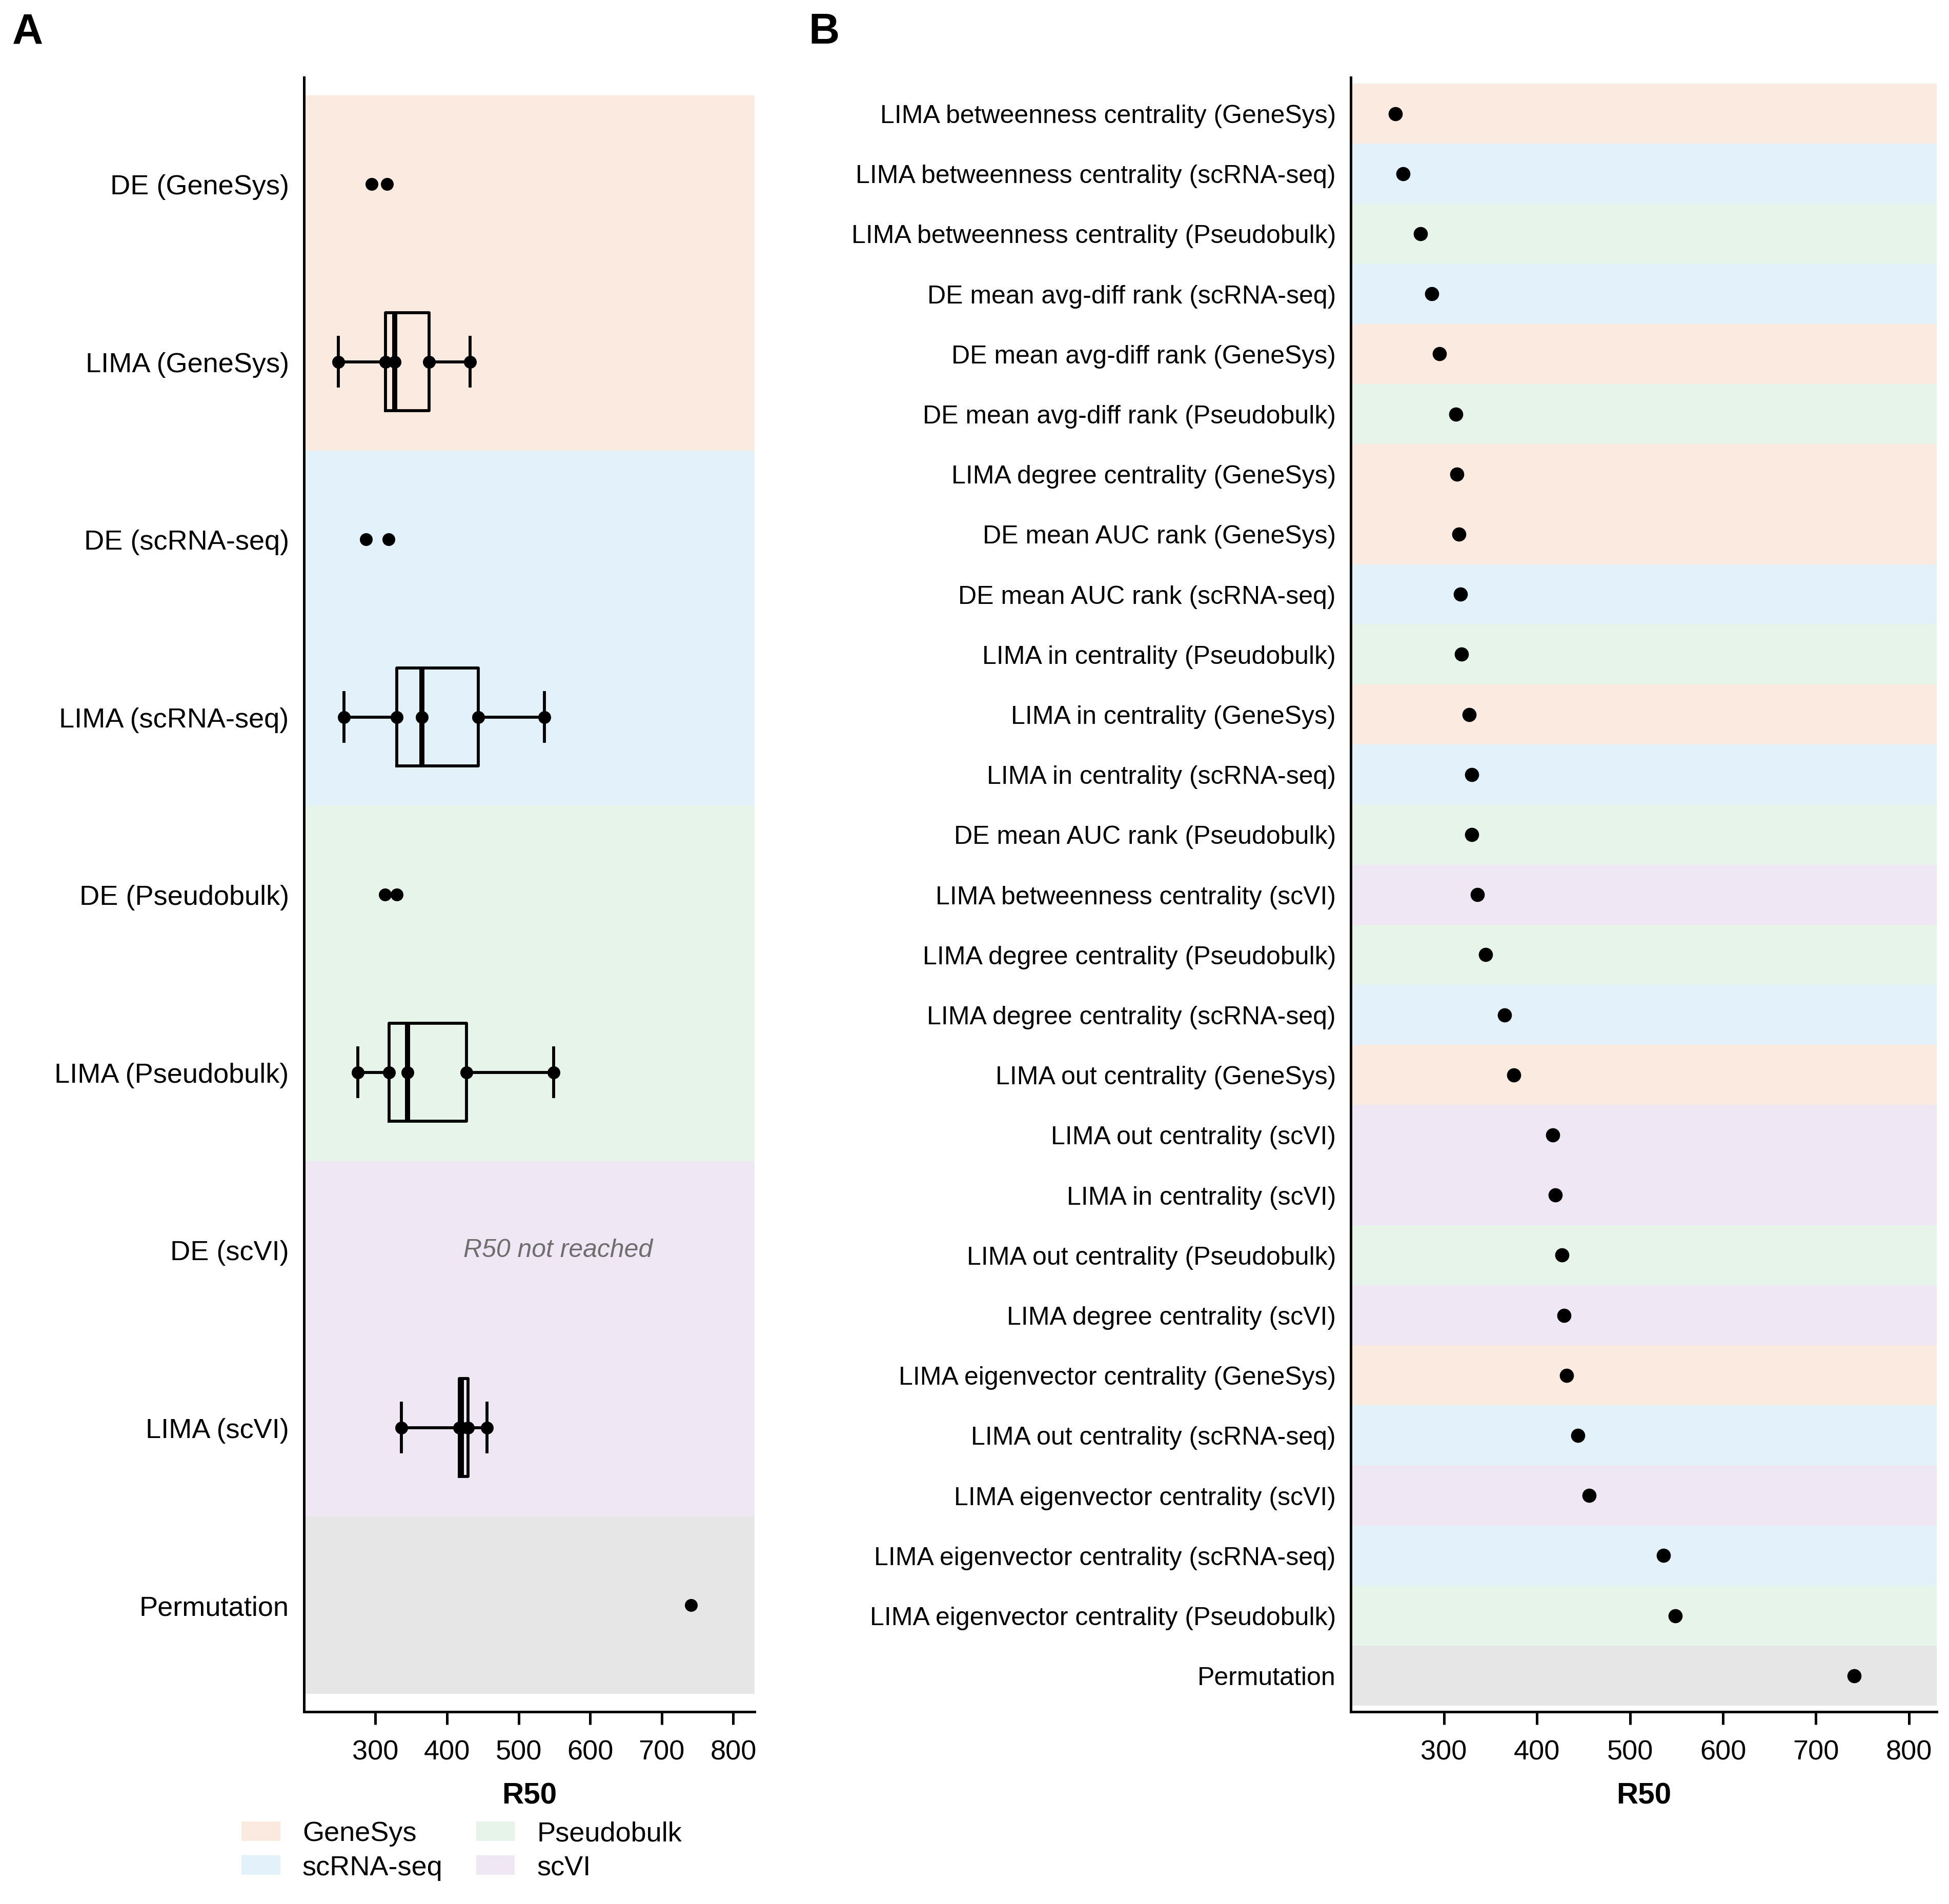

In [14]:
figures.figure4_expanded()   # Figure 5, drawn from the tables above
display(Image(os.path.join(R, 'figures', 'fig5_benchmark_conditions.png'), width=850))

## 5. Experiment 6: GRNBoost2 in place of the least-squares fit (Figure S11A)

GRNBoost2 replaces the least-squares fit of LIMA on GeneSys-generated data and the remaining steps are unchanged. `exp29_grnboost_states.py` generates, for each transition, eleven batches of 2,000 blueprint trajectories with the trained model (200 trajectories per cell type and batch, about 2,200 paired state rows per cell type) and stores the expression of the 1,495 TFs at the two states. `exp30_grnboost_fit.py` regresses every TF at the later state on all other TFs at the earlier state with the gradient-boosting settings and the early-stopping rule of arboreto. `exp31_condition_centrality.py` thresholds each regulator-by-target importance matrix at |z| > 3 and computes the same five centralities with the same network code as LIMA, and `exp13_fig4_r50.py` scores them.

In [15]:
# Commands used on the cluster (not executed here):
#   sbatch --gres=gpu:nvidia_h200:1 experiments/slurm/run_gpu.sh experiments/exp29_grnboost_states.py --condition genesys
#   sbatch --cpus-per-task=32 --mem=64G experiments/slurm/run_arboreto_cpu.sh experiments/exp30_grnboost_fit.py --condition genesys --transition t1-t3 --n-jobs 32   # one job per transition
#   sbatch experiments/slurm/run_cpu.sh experiments/exp31_condition_centrality.py --source grnboost --condition genesys
#   bash experiments/slurm/post_grnboost.sh       # exp13 scoring, then the benchmark table and figures

In [16]:
gb_src = pd.read_csv(os.path.join(P, 'exp13_r50_grnboost_genesys.csv'))
gb = gb_src[gb_src['panel'] == 'All'].set_index('strategy')['R50'].loc[lima.index]
cmp = pd.DataFrame({'LIMA': lima['genesys'].astype(int), 'GRNBoost2': gb})
print(cmp.to_string())

assert gb.to_dict() == {'degree_centrality': 560, 'out_centrality': 561, 'in_centrality': 629,
                        'betweenness_centrality': 453, 'eigenvector_centrality': 771}
stored_gb = tab[tab['method'] == 'GRNBoost2'].set_index('strategy')['R50']
assert (stored_gb.loc[gb.index].values == gb.values).all()

assert (cmp['GRNBoost2'] > cmp['LIMA']).all()                         # "Every GRNBoost2 centrality metric gave a higher R50 than the corresponding LIMA metric"
assert gb['eigenvector_centrality'] >= PERM                           # "eigenvector centrality fell to the permutation baseline"
assert (gb.drop('eigenvector_centrality') < PERM).all()

                        LIMA  GRNBoost2
strategy                               
degree_centrality        314        560
out_centrality           375        561
in_centrality            327        629
betweenness_centrality   248        453
eigenvector_centrality   432        771


## 6. Experiment 5: in silico knockout, ranking of TFs (Figure S11A)

`exp17_knockout_ranking.py` sets each of the 17,513 genes to zero across all time bins of 100 blueprint-assembled test sequences (10 per trajectory) and generates transcriptomes from the knocked-out input with the model's own functions. Two protocols of the author's notebook 4 were run:

* **fully seeded** (cells 144 to 147, the protocol behind Figure 2; `--protocol seeded`, the default and the one reported in the manuscript): t0 from `generate_current`, then the next state from every time bin of the input with `generate_next`, with `predict_proba` carrying the hidden state. The gene is absent at every time bin.
* **rollout** (cells 179 to 180; `--protocol rollout`): the model is seeded with t0 to t2 and generates the remaining bins autoregressively. The gene is absent only in the three seed bins.

The model is in evaluation mode and the random number generator is reset to the same seed for the unperturbed run and for every knockout, so that all runs draw the same latent noise and differ only by the knockout. Two effects are recorded per gene: the generative effect (one minus the cosine similarity between the transcriptomes generated with and without the gene, averaged over sequences and over t0 to t10) and the classifier effect (total-variation distance between the predicted cell type probabilities, averaged over sequences and over t1 to t10). The combined effect is the sum of the two after min-max scaling.

In [17]:
# Command used on the cluster (not executed here):
#   sbatch --job-name=rc_exp17s --gres=gpu:nvidia_h200:1 experiments/slurm/run_gpu_fast.sh experiments/exp17_knockout_ranking.py --protocol seeded
#   sbatch --job-name=rc_exp17  --gres=gpu:nvidia_h200:1 experiments/slurm/run_gpu_fast.sh experiments/exp17_knockout_ranking.py --protocol rollout

In [18]:
ko = pd.read_csv(os.path.join(P, 'exp17_knockout', 'exp17_knockout_scores.csv'))
assert list(ko['GeneID']) == genes

EFFECTS = ['gen_effect', 'cls_effect', 'combined_effect']
ko_r50 = {}
for col in EFFECTS:
    ranked = ko.sort_values(col, ascending=False, kind='stable')
    ko_r50[col] = r50_scan(ranked.loc[ranked['GeneID'].isin(exptf_set), 'GeneID'].values, gold)   # ranked among the 1,495 TFs
print('knockout R50 among the 1,495 TFs:', ko_r50)

assert ko_r50 == {'gen_effect': 416, 'cls_effect': 834, 'combined_effect': 489}
assert all(ko_summary[c]['r50_within_tf'] == ko_r50[c] for c in EFFECTS)
stored_ko = tab[tab['method'] == 'Knockout'].set_index('strategy')['R50']
assert all(stored_ko[c] == ko_r50[c] for c in EFFECTS)

# "Ranked by any of the three effects, the gold-standard TFs were recovered less efficiently than by four of the five LIMA centrality metrics"
for c in EFFECTS:
    assert (lima['genesys'] < ko_r50[c]).sum() >= 4
assert (lima['genesys'] < ko_r50['gen_effect']).sum() == 4            # the generative effect is ahead of eigenvector centrality only
# "the classifier effect fell behind the permutation baseline"
assert ko_r50['cls_effect'] > PERM and ko_r50['gen_effect'] < PERM and ko_r50['combined_effect'] < PERM

# the rollout protocol, for comparison
ko_roll = json.load(open(os.path.join(P, 'exp17_knockout_rollout', 'exp17_summary.json')))
roll = {c: ko_roll[c]['r50_within_tf'] for c in EFFECTS}
print('rollout protocol, R50 among the 1,495 TFs:', roll)
assert roll == {'gen_effect': 680, 'cls_effect': 738, 'combined_effect': 660}

# the effects are small in absolute terms; only their ranking is used
print(ko[EFFECTS].describe().loc[['50%', 'max']].to_string())

knockout R50 among the 1,495 TFs: {'gen_effect': 416, 'cls_effect': 834, 'combined_effect': 489}
rollout protocol, R50 among the 1,495 TFs: {'gen_effect': 680, 'cls_effect': 738, 'combined_effect': 660}


       gen_effect    cls_effect  combined_effect
50%  1.731786e-07  3.221587e-13         0.013521
max  2.220983e-05  7.418387e-11         1.289575


## 7. Experiment 7: genome-wide recall of the gold standard (Figure S11B to S11D)

Here all 17,513 genes are ranked and recall is the fraction of the 140 gold-standard TFs among the top K genes.

### 7.1 Knockout scores

In [19]:
KS = [100, 200, 300, 400]
N = len(genes)
gene_arr = np.array(genes)

def top(scores, K):
    return set(gene_arr[np.argsort(-np.asarray(scores), kind='stable')[:K]])

rows = []
for col in EFFECTS:
    for K in KS:
        t = top(ko[col].values, K)
        hits, tf_hits = len(t & gold), len(t & tf_annot)
        rows.append(dict(score=col, K=K, gold_hits=hits, expected=K * len(gold) / N,
                         p_gold=hypergeom.sf(hits - 1, N, len(gold), K),
                         tf_hits=tf_hits, tf_expected=K * len(exptf) / N))
gw = pd.DataFrame(rows)
print(gw.round({'expected': 1, 'tf_expected': 1}).to_string(index=False))

g400 = gw[(gw['score'] == 'gen_effect') & (gw['K'] == 400)].iloc[0]
assert g400['gold_hits'] == 11                                        # "11 of the 140 gold-standard TFs among its top 400 genes"
assert round(g400['gold_hits'] / g400['expected'], 1) == 3.4          # "3.4 times the chance expectation"
assert f"{g400['p_gold']:.0e}" == '4e-04'                             # "hypergeometric p = 4 x 10^-4"
assert round(g400['expected']) == 3                                   # "against 3 expected by chance"
assert g400['gold_hits'] / len(gold) < 0.1                            # "less than a tenth of the gold standard among the top 400 genes"
assert (g400['tf_hits'], round(g400['tf_expected'])) == (34, 34)      # "34 annotated TFs against 34 expected"

# same numbers in the stored audit (exp27_knockout_audit.py)
audit = json.load(open(os.path.join(P, 'exp27_knockout_audit.json')))
a400 = [r for r in audit['gen_effect'] if r['K'] == 400][0]
assert (a400['gold_hits'], a400['tf_hits']) == (11, 34) and abs(a400['p_gold'] - g400['p_gold']) < 1e-12

# the rollout protocol: 2 of 140 in the top 400, at chance
roll400 = round(ko_roll['gen_effect']['genomewide_recall']['400'] * 140)
print('rollout protocol, gold-standard TFs in the top 400 by the generative effect:', roll400)
assert roll400 == 2

          score   K  gold_hits  expected   p_gold  tf_hits  tf_expected
     gen_effect 100          0       0.8 1.000000        4          8.5
     gen_effect 200          3       1.6 0.215302       11         17.1
     gen_effect 300          8       2.4 0.002868       24         25.6
     gen_effect 400         11       3.2 0.000374       34         34.1
     cls_effect 100          0       0.8 1.000000        5          8.5
     cls_effect 200          0       1.6 1.000000       13         17.1
     cls_effect 300          1       2.4 0.911851       21         25.6
     cls_effect 400          1       3.2 0.961139       29         34.1
combined_effect 100          0       0.8 1.000000        5          8.5
combined_effect 200          1       1.6 0.801003        9         17.1
combined_effect 300          4       2.4 0.219284       17         25.6
combined_effect 400          6       3.2 0.101928       27         34.1
rollout protocol, gold-standard TFs in the top 400 by the genera

### 7.2 Is the knockout enrichment explained by expression level?

`exp26_gene_expression_stats.py` stores the mean expression, detection rate and variance of every gene across the test cells. `exp27_knockout_audit.py` ranks the genes by each of these, and re-ranks the knockout generative effect after removing its rank-linear dependence on mean expression (residual of the rank of the knockout score regressed on the rank of mean expression).

In [20]:
# Commands (not executed here):
#   sbatch experiments/slurm/run_cpu.sh experiments/exp26_gene_expression_stats.py
#   python experiments/exp27_knockout_audit.py

In [21]:
st = pd.read_csv(os.path.join(P, 'exp26_gene_expression_stats.csv')).set_index('GeneID').loc[genes]

by_expr = {K: len(top(st['mean_expr'].values, K) & gold) for K in KS}
print('gold-standard TFs among the top K genes by mean expression:', by_expr)
assert by_expr[400] == 1                                              # "recovers one gold-standard TF among the top 400"

rho = spearmanr(st['mean_expr'].values, ko['gen_effect'].values).correlation
print(f'Spearman correlation, knockout generative effect vs mean expression: {rho:.2f}')
assert round(rho, 2) == 0.41

r_ko, r_ex = rankdata(ko['gen_effect'].values), rankdata(st['mean_expr'].values)
resid = r_ko - np.polyval(np.polyfit(r_ex, r_ko, 1), r_ex)
adj = {K: len(top(resid, K) & gold) for K in KS}
print('gold-standard TFs among the top K genes after removing the dependence on mean expression:', adj)
assert adj[400] == 9                                                  # "9 gold-standard TFs remain among the top 400, against 3 expected by chance"
p_adj = hypergeom.sf(adj[400] - 1, N, len(gold), 400)
print(f'hypergeometric p for 9 of 400: {p_adj:.3f}')
assert round(p_adj, 3) == 0.005

# stored audit agrees
assert [r['gold_hits'] for r in audit['gen_effect_residualized_on_expression']] == [adj[K] for K in KS]
assert [r['gold_hits'] for r in audit['confound_mean_expr']['rows']] == [by_expr[K] for K in KS]

gold-standard TFs among the top K genes by mean expression: {100: 0, 200: 0, 300: 0, 400: 1}
Spearman correlation, knockout generative effect vs mean expression: 0.41
gold-standard TFs among the top K genes after removing the dependence on mean expression: {100: 3, 200: 4, 300: 8, 400: 9}
hypergeometric p for 9 of 400: 0.005


### 7.3 LIMA degree centrality and DE in the four scenarios

`exp18_genomewide_recall.py` ranks all genes by LIMA degree centrality and by DE in each scenario. For LIMA, every cell type matrix of every transition is thresholded at |z| > 3 and the degree of a gene is the number of retained edges in its row and column, summed over the ten cell types and the five transitions. For DE, the genes are ordered by their mean AUC over the clusters in which they are markers (the four marker tables of section 4.2: the Figure 4 tables for the GeneSys-generated and unregularized scenarios, the port tables for pseudobulk and scVI); genes that are not markers are ranked last.

In [22]:
# Command (not executed here):
#   sbatch --job-name=exp18_gw experiments/slurm/run_cpu.sh experiments/exp18_genomewide_recall.py

In [23]:
rec = pd.read_csv(os.path.join(P, 'exp18_genomewide_recall.csv'))
hits = rec.set_index(['method', 'condition']).mul(140).round().astype(int)
hits.columns = [f'hits in top {K}' for K in KS]
chance = [K * 140 / N for K in KS]
print(hits.drop(index=('expected_by_chance', 'random')).to_string())
print('\nexpected by chance:', [round(c, 1) for c in chance])

# the DE rows are reproduced from the marker tables
for cond, stem in files.items():
    m = pd.read_csv(os.path.join(P, 'markers', stem))
    score = pd.Series(-1.0, index=genes); mean_auc = m.groupby('gene')['myAUC'].mean()
    score.loc[mean_auc.index] = mean_auc.values
    assert [len(top(score.values, K) & gold) for K in KS] == list(hits.loc[('DE_myAUC', cond)])
# the knockout rows are those of section 7.1
for col in EFFECTS:
    assert list(hits.loc[(f'knockout_{col}', 'genesys')]) == list(gw[gw['score'] == col]['gold_hits'])

                                     hits in top 100  hits in top 200  hits in top 300  hits in top 400
method                   condition                                                                     
LIMA_degree              genesys                   0                0                1                3
                         scrnaseq                  0                1                3                5
                         pseudobulk                1                1                3                6
                         scvi                      0                0                2                2
DE_myAUC                 genesys                   0                2                4                6
                         scrnaseq                  2                4                7               10
                         pseudobulk                3                4                4                4
                         scvi                      2            

In [24]:
at400 = hits['hits in top 400'].drop(index=('expected_by_chance', 'random'))
p400 = at400.apply(lambda h: hypergeom.sf(h - 1, N, 140, 400))
summary = pd.DataFrame({'hits in top 400': at400, 'fold over chance': (at400 / chance[3]).round(1), 'hypergeometric p': p400.round(4)})
print(summary.to_string())

lima400, de400 = at400['LIMA_degree'], at400['DE_myAUC']
assert lima400.to_dict() == {'genesys': 3, 'scrnaseq': 5, 'pseudobulk': 6, 'scvi': 2}
assert de400.to_dict() == {'genesys': 6, 'scrnaseq': 10, 'pseudobulk': 4, 'scvi': 11}

# on GeneSys-generated data (Figure S11B) the knockout generative effect recovers the most gold-standard TFs
gen_data = at400.xs('genesys', level='condition')
assert gen_data.idxmax() == 'knockout_gen_effect' and gen_data.max() == 11
assert (gen_data.drop('knockout_gen_effect') < 11).all()
# across all scenarios DE on scVI-denoised data reaches the same count
assert at400.max() == 11 and de400['scvi'] == 11
# "no expression-derived ranking tested here recovers more than a tenth of the gold-standard transcription factors among the top 400 genes"
assert at400.max() <= 14
# on GeneSys-generated data: LIMA degree centrality at chance, DE above it, knockout generative effect far above
assert lima400['genesys'] == round(chance[3]) and de400['genesys'] > chance[3]

                                     hits in top 400  fold over chance  hypergeometric p
method                   condition                                                      
LIMA_degree              genesys                   3               0.9            0.6235
                         scrnaseq                  5               1.6            0.2167
                         pseudobulk                6               1.9            0.1019
                         scvi                      2               0.6            0.8329
DE_myAUC                 genesys                   6               1.9            0.1019
                         scrnaseq                 10               3.1            0.0014
                         pseudobulk                4               1.3            0.3976
                         scvi                     11               3.4            0.0004
knockout_gen_effect      genesys                  11               3.4            0.0004
knockout_cls_effect  

Reading of the table. On GeneSys-generated data (Figure S11B) LIMA degree centrality recovers 3 gold-standard TFs in the top 400, which is the chance expectation, DE recovers 6 and the knockout generative effect 11. Across the four scenarios (Figure S11C and S11D) LIMA degree centrality recovers 2 to 6 and DE 4 to 11 against 3.2 expected. The hypergeometric p-values in the table show which of these differ from chance at K = 400: the knockout generative effect, and DE on the unregularized and scVI-denoised data.

  saved figS_genomewide.pdf / .png / .tif  (6.00 x 4.75 in at 600 dpi)


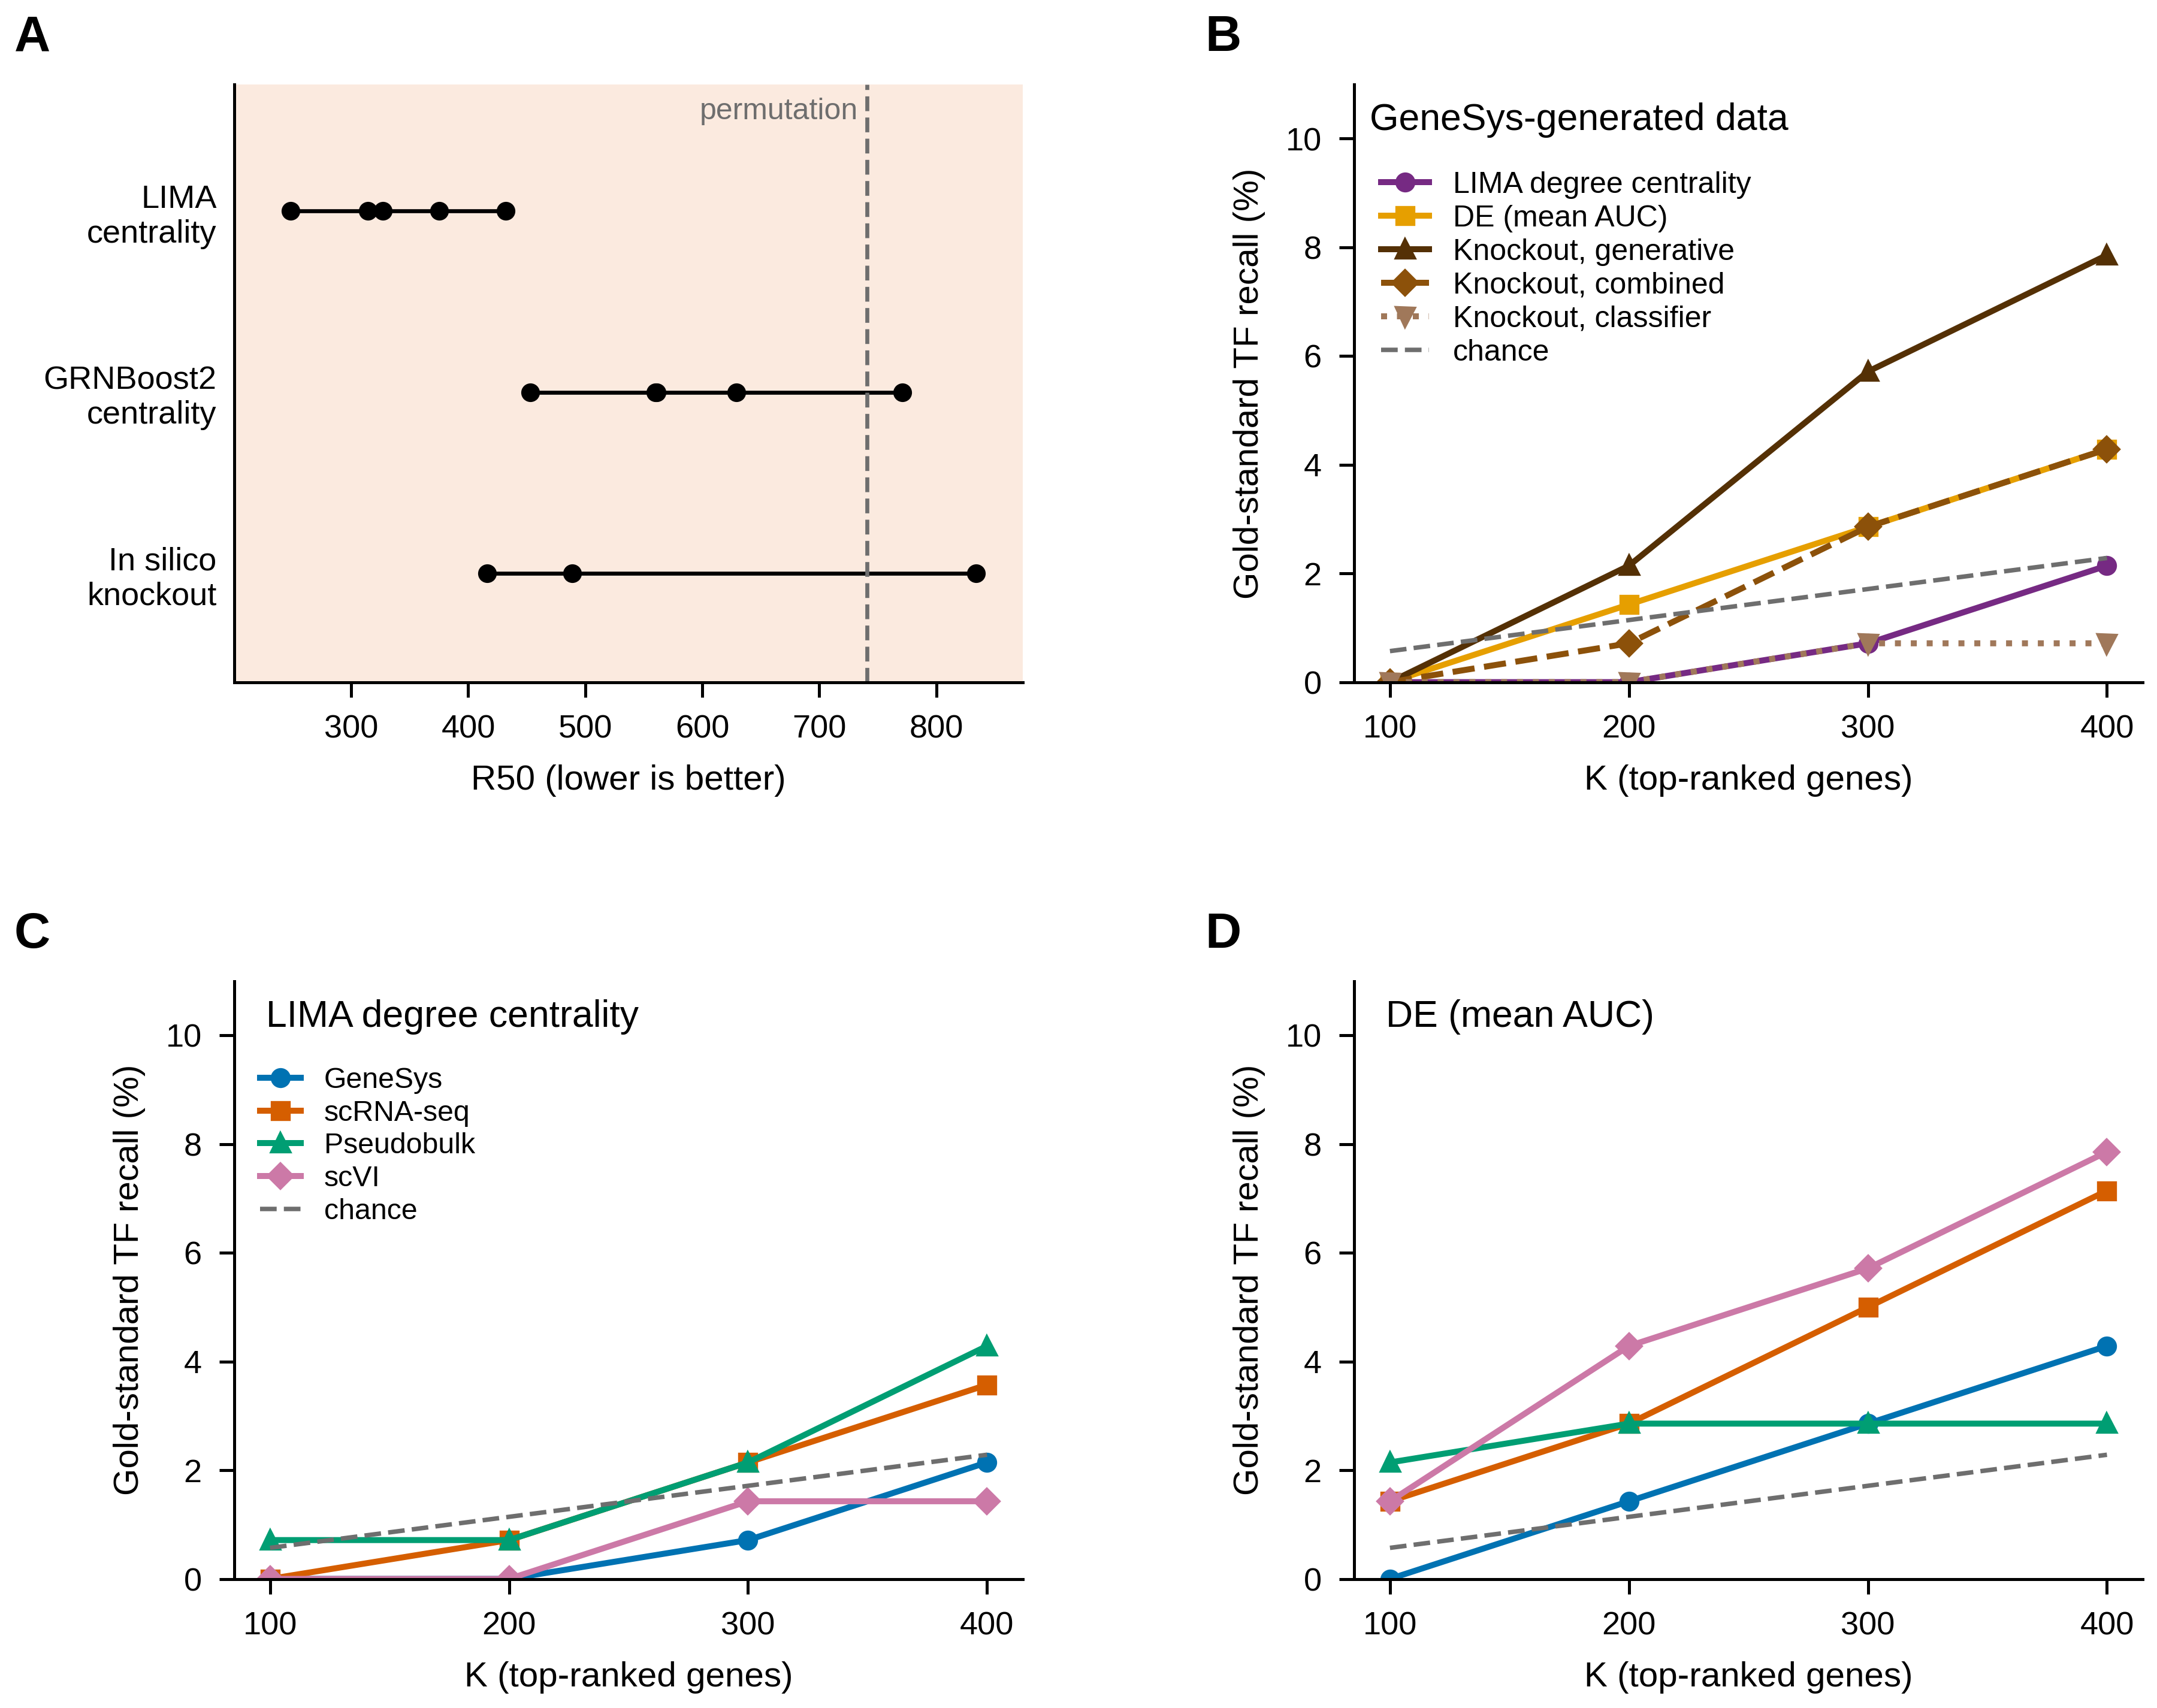

In [25]:
figures.figure_genomewide()   # Figure S11, drawn from the tables above
display(Image(os.path.join(R, 'figures', 'figS_genomewide.png'), width=850))